In [1]:
import os, glob
import numpy as np
import pandas as pd
import scanpy as sc
from pygam import LinearGAM, s
import matplotlib.pyplot as plt
from adjustText import adjust_text

In [2]:
pth = os.path.join('..', '..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'human', 'NMT')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_ref = os.path.join(pth_data, 'ref', 'AnimalTFDBv4')
pth_out = os.path.join(pth, 'figures', 'cancer', 'human', 'NMT', 'features')

In [3]:
fn = os.path.join(pth_ref, 'Homo_sapiens_TF')
tf = pd.read_csv(fn, sep = '\t').Symbol.tolist()

In [4]:
feat_fn = sorted(glob.glob(os.path.join(pth_feat, '*.csv')))
get_src = lambda fn: os.path.split(fn)[1].replace('.csv', '')
feat_dict = {get_src(fn) : pd.read_csv(fn) for fn in feat_fn}

In [5]:
adata = sc.read_h5ad(os.path.join(pth_in, 'trajectory.h5ad'))
adata

AnnData object with n_obs × n_vars = 5101 × 19695
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'percent.RPL', 'percent.RPS', 'S.Score', 'G2M.Score', 'Phase', 'CC.Difference', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.8', 'seurat_clusters', 'ident', 'celltype', 't', 'seg', 'edge', 'milestones'
    uns: 'Phase_colors', 'X_name', 'celltype_colors', 'graph', 'ident_colors', 'log1p', 'milestones_colors', 'pseudotime_list', 'seg_colors'
    obsm: 'UMAP.GRAPH', 'X_R', 'X_pca', 'X_umap'
    layers: 'logcounts'

In [6]:
def fit_gam(Y, X, n_spl, n_pts):
    GAM = LinearGAM(s(0, n_splines = n_spl))
    GAM = GAM.fit(X, Y)
    xx = np.linspace(X.min(), X.max(), n_pts)
    return GAM.predict(xx)

def scale_01(Y):
    return (Y - Y.min()) / (Y.max() - Y.min())

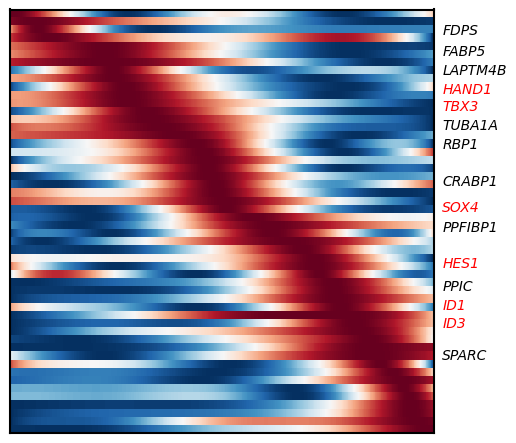

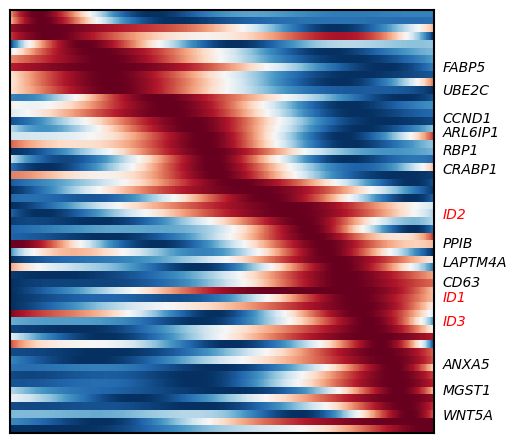

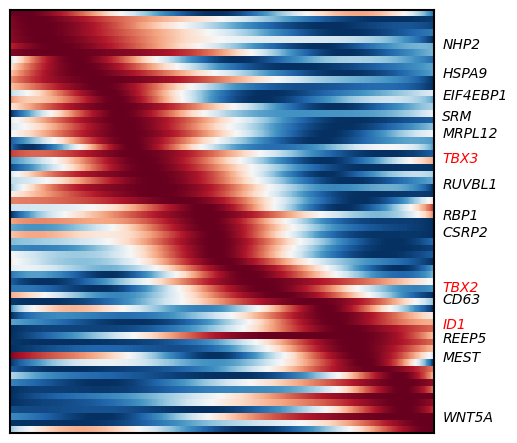

In [8]:
# feature GAMs
n_pts, n_spl = 500, 7
t = adata.obs.t.values.copy()
for src, df_src in feat_dict.items():
    if src != 'union':
        g = df_src.hsapiens.drop_duplicates()
        g = (g.loc[g.isin(adata.var_names)]
             .reset_index(drop = True))
        
        # fit GAMs
        X = np.zeros((g.size, n_pts))
        A = np.zeros(g.size)
        for i, name in g.items():
            Y = adata[:, name].X.toarray()
            if np.unique(Y).size > 1:
                Yf = fit_gam(Y, t, n_spl, n_pts)
                X[i] = scale_01(Yf)
                A[i] = np.ptp(Yf)

        # select, order features
        ixmax = X.argmax(axis = 1)
        msk = (ixmax > 0) & (ixmax < (n_pts - 1))
        order = ixmax[msk].argsort()
        X_plt = X[msk][order].copy()
        A_plt = A[msk][order].copy()
        A_rank = np.argsort(np.argsort(-A_plt))

        # plot heatmap
        aspect = 500 / msk.sum()
        fig, ax = plt.subplots(1, 1, figsize = (6, 5.5))
        ax.imshow(X_plt, aspect = aspect, interpolation = 'nearest', cmap = 'RdBu_r')
        ax.set_yticks(np.arange(X_plt.shape[0]), g.loc[msk].iloc[order].copy())
        ax.set_xticks([])

        # label top features
        n_feat, texts = 15, list()
        for i, label in enumerate(ax.get_yticklabels()):
            if A_rank[i] < n_feat:
                _label_ = label.get_text()
                c = 'r' if _label_ in tf else 'k'
                texts.append(
                    ax.annotate(_label_, (0, i),
                                va = 'center',
                                ha = 'left',
                                fontsize = 10,
                                fontstyle = 'italic',
                                color = c))
        ax.set_yticks([])

        # adjust labels
        keys = ('text', 'static', 'explode', 'pull')
        only_move = {key : 'y' for key in keys}
        adjust_text(texts, only_move = only_move)
        for txt in texts:
            pos = txt.get_position()
            txt.set_position((n_pts + 10, pos[1]))
            txt.set_ha('left')

        for sp in ax.spines.values(): sp.set_linewidth(1.5)
        fn = os.path.join(pth_out, f'{src}.pdf')
        plt.savefig(fn, bbox_inches = 'tight')

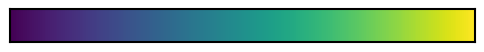

In [9]:
fig, ax = plt.subplots(1, 1, figsize = (6, 5.5))
xx = np.linspace(t.min(), t.max(), n_pts).reshape(1, -1)
ax.imshow(xx, aspect = 35, interpolation = 'nearest', cmap = 'viridis')
ax.set_yticks([]); ax.set_xticks([])
for sp in ax.spines.values(): sp.set_linewidth(1.5)
fn = os.path.join(pth_out, 't.pdf')
plt.savefig(fn, bbox_inches = 'tight')